# Tiny JEPA Lab: от пикселей к прогнозу

Здесь можно запустить уже обученную маленькую модель и посмотреть, что именно она делает.
**JEPA прогнозирует представление, а не картинку.** Это учебная реализация с EMA-учителем
и VICReg-подобными ограничениями, не полная Meta V-JEPA.

Запускайте notebook из распакованной папки проекта. Установка: `pip install -r requirements-notebook.txt`.
Все данные синтетические; интернет и GPU после установки не нужны.

In [1]:
from pathlib import Path
import sys, json
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "tinyjepa").is_dir() and (ROOT / "tiny_jepa_lab/tinyjepa").is_dir():
    ROOT = ROOT / "tiny_jepa_lab"
if not (ROOT / "tinyjepa").is_dir():
    raise RuntimeError("Откройте notebook из распакованной папки tiny_jepa_lab")
sys.path.insert(0, str(ROOT))
from tinyjepa.core import World, TinyJEPA, Config, load_model, jepa_loss
from tinyjepa.evaluation import load_probe, measure

torch.set_num_threads(2)
model = load_model(ROOT / "artifacts/pretrained")
probe = load_probe(ROOT / "artifacts/pretrained", model.cfg.dim)
print("PyTorch:", torch.__version__)
print("Параметров encoder + predictor:", model.inference_parameter_count())
print("Размер представления:", model.cfg.dim)

PyTorch: 2.10.0+cpu
Параметров encoder + predictor: 103888
Размер представления: 8


## 1. Что получает сеть

Два последовательных кадра и горизонт h. Координаты, которые знает симулятор,
в `model(...)` не передаются. Будущий кадр сейчас не показываем.

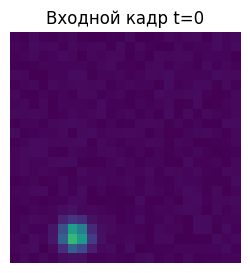

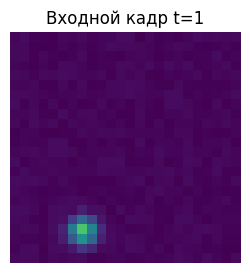

Горизонт прогноза: 4


In [2]:
batch = World(model.cfg, seed=202611).sample(8)
i = 0
for t in range(2):
    plt.figure(figsize=(3, 3))
    plt.imshow(batch.context[i, t].numpy(), vmin=0, vmax=1)
    plt.title(f"Входной кадр t={t}")
    plt.axis("off")
    plt.show()
print("Горизонт прогноза:", int(batch.horizon[i]))

## 2. Нейросеть выдаёт восемь чисел

Первые две строки ниже — сам JEPA-прогноз. `probe` — отдельный измерительный прибор:
он обучен с координатными метками **после заморозки JEPA**, только на представлениях
наблюдаемых кадров. Он нужен, чтобы человеку было удобно увидеть результат.

Предсказанные признаки: [-1.478, 0.578, 1.065, 0.313, -0.199, -1.305, -0.568, -0.906]
Координаты через отдельный readout: [0.4736913740634918, 0.6980816125869751]
Истинные координаты (только для проверки): [0.44527775049209595, 0.6281793117523193]
Ошибка на первой траектории: 1.735 пикселя


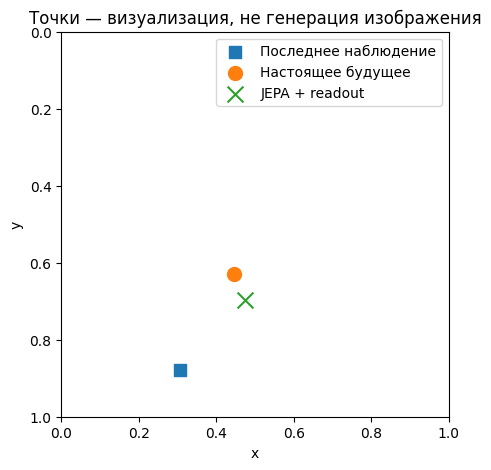

In [3]:
with torch.no_grad():
    predicted_z, context_z = model(batch.context, batch.horizon)
    predicted_xy = probe(predicted_z)
    actual_z = model.teacher(batch.future)
print("Предсказанные признаки:", [round(float(v), 3) for v in predicted_z[i]])
print("Координаты через отдельный readout:", predicted_xy[i].tolist())
print("Истинные координаты (только для проверки):", batch.positions[i, 2].tolist())
error = ((predicted_xy - batch.positions[:, 2]) * (model.cfg.size - 1)).norm(dim=1)
print("Ошибка на первой траектории:", round(float(error[i]), 3), "пикселя")
plt.figure(figsize=(5, 5))
plt.scatter(*batch.positions[i, 1].tolist(), marker="s", s=80, label="Последнее наблюдение")
plt.scatter(*batch.positions[i, 2].tolist(), marker="o", s=100, label="Настоящее будущее")
plt.scatter(*predicted_xy[i].tolist(), marker="x", s=130, label="JEPA + readout")
plt.xlim(0, 1); plt.ylim(1, 0)
plt.xlabel("x"); plt.ylabel("y"); plt.legend()
plt.title("Точки — визуализация, не генерация изображения")
plt.show()

## 3. Что значит «учится без меток»

Ниже создаётся **новая**, необученная модель, чтобы показать несколько шагов обучения.
Готовые веса не изменяются. В loss входят изображения и горизонт — координатных меток нет.
Учитель заморожен для градиента и обновляется скользящим средним.

In [4]:
torch.manual_seed(42)
student = TinyJEPA(Config())
world = World(student.cfg, seed=42)
optimizer = torch.optim.AdamW([p for p in student.parameters() if p.requires_grad], lr=0.001)
for step in range(10):
    b = world.sample(128)
    loss, logs = jepa_loss(student, b.context, b.future, b.horizon)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(student.parameters(), 5.0)
    optimizer.step()
    student.update_teacher()
print("Последний учебный шаг:", {k: round(v, 5) for k, v in logs.items()})
print("Градиенты учителя отсутствуют:", all(p.grad is None for p in student.teacher.parameters()))
print("10 шагов показывают механику, а не завершённое обучение.")

Последний учебный шаг: {'loss': 9.65266, 'prediction_mse': 0.00122, 'variance_penalty': 0.96405, 'covariance_penalty': 0.0}
Градиенты учителя отсутствуют: True
10 шагов показывают механику, а не завершённое обучение.


## 4. Контроль качества на независимых данных

Метрики уже получены полноценным `evaluate.py`: 2 048 траекторий на режим,
отдельные seeds для probe и теста. Координатная ошибка — евклидово расстояние.
Явный физический baseline знает закон отражения и в этой задаче лучше нейросети.

In [5]:
metrics = json.loads((ROOT / "artifacts/pretrained/metrics.json").read_text())
for mode in ["in_distribution", "high_noise", "double_speed"]:
    r = metrics[mode]
    print(f"{mode}: JEPA {r['jepa_error']['mean']:.3f} px | "
          f"стоит на месте {r['stationary_error']['mean']:.3f} px | "
          f"явная физика {r['physics_error']['mean']:.3f} px")
print("Ошибка readout на наблюдаемом кадре:", round(metrics['in_distribution']['probe_error']['mean'], 3))
print("Линейный probe на наблюдаемом кадре:", round(metrics['in_distribution']['linear_observed_probe_error_px'], 3))

in_distribution: JEPA 0.823 px | стоит на месте 3.412 px | явная физика 0.260 px
high_noise: JEPA 4.732 px | стоит на месте 3.389 px | явная физика 0.438 px
double_speed: JEPA 3.004 px | стоит на месте 6.365 px | явная физика 0.786 px
Ошибка readout на наблюдаемом кадре: 0.23
Линейный probe на наблюдаемом кадре: 2.674


## 5. Почему минимальный loss — не всегда успех

У модели без регуляризации почти исчезает разброс признаков. В таком масштабе
предсказывать их легко, но полезное содержание сильно ухудшается. Не сравнивайте
только сырые MSE разных выученных пространств. Смотрите std, качество downstream
задачи и baseline.

In [6]:
for directory in ["pretrained", "no_regularization"]:
    r = json.loads((ROOT / "artifacts" / directory / "metrics.json").read_text())["in_distribution"]
    print(f"{directory}: latent MSE={r['latent_mse']['mean']:.3e}; "
          f"std={r['representation']['mean_std']:.6f}; "
          f"position error={r['jepa_error']['mean']:.3f} px")

pretrained: latent MSE=5.267e-02; std=1.050492; position error=0.823 px
no_regularization: latent MSE=2.443e-07; std=0.000598; position error=5.983 px


## 6. Собственное обучение и эксперименты

В терминале из папки проекта:

```bash
python train.py --out runs/my_jepa --steps 2400
python evaluate.py --model runs/my_jepa
python export_demo.py --model runs/my_jepa --output my_demo.html
```

Начните с `docs/EXERCISES_RU.md`. Самый простой опыт: повторите последний кадр дважды
или поменяйте порядок входных кадров, не меняя целевой кадр. Сравните ошибки на
новом фиксированном наборе. Это вмешательство во вход при inference, не полноценная
абляция обучения.

**Границы вывода:** один шарик, простой фон, короткие горизонты, одна основная
инициализация. Нет действий или планирования. Результат не доказывает превосходства
над LLM и не переносится автоматически на реальное видео.

Первичные источники: [V-JEPA](https://github.com/facebookresearch/jepa),
[VICReg](https://github.com/facebookresearch/vicreg).